
# # Config B — So sánh 4 mô hình hồi quy
## Mục tiêu: so sánh Linear Regression, Random Forest,Gradient Boosting và MLP trên cùng cấu hình đặc trưng B.

- Đặc trưng: thời gian, ngày lễ và thời tiết.
- Huấn luyện trên train, so sánh trên validation.
- Chỉ số: MAE, RMSE và R²; ưu tiên MAE để xếp hạng.



**Nguồn dữ liệu chung (19/11/2026):** Code đọc dữ liệu đã chuyển sang `src.experiment_data.load_experiment_splits`. `processed` dùng snapshot bàn giao; `raw` dùng cho CV trước điền thiếu; `filled` giữ schema nhãn và học điền từ train. Các output/metrics đang hiển thị là kết quả lịch sử, chưa chạy lại sau thay đổi này.


## Params

In [1]:
EXPERIMENT_NAME = "ConfigB_Phuc"
CONFIG_NAME = "B"
TARGET = "traffic_volume"
RANDOM_STATE = 42
PRIMARY_METRIC = "MAE"

# Các tùy chọn xử lý dữ liệu đang có trong src/data.py.
DATA_PARAMS = {
    "mask_stuck_temp": False,
    "complete_holidays": False,
}

# Params truyền trực tiếp vào estimator qua make_fixed_model().
# Không dùng tiền tố model__ ở đây.
MODEL_PARAMS = {
    "Linear Regression": {
        "fit_intercept": True,
    },
    "Random Forest": {
        "n_estimators": 200,
        "max_depth": 12,
        "min_samples_leaf": 5,
        "random_state": 42,
        "n_jobs": -1,
    },
    "Gradient Boosting": {
        "n_estimators": 200,
        "learning_rate": 0.05,
        "max_depth": 3,
        "min_samples_leaf": 5,
        "loss": "squared_error",
        "random_state": 42,
    },
    "MLP": {
        "hidden_layer_sizes": (64, 32),
        "activation": "relu",
        "solver": "adam",
        "alpha": 0.0001,
        "learning_rate_init": 0.001,
        "batch_size": 128,
        "max_iter": 500,
        "random_state": 42,
    },
}

## Import và tìm thư mục dự án

In [2]:

import json
import sys
import warnings
from pathlib import Path
from datetime import datetime, timezone, timedelta
from time import perf_counter

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


def find_project_root():
    current = Path.cwd().resolve()

    for folder in (current, *current.parents):
        for candidate in (
            folder,
            folder / "metro_interstate_traffic_volume",
        ):
            if (
                (candidate / "src" / "models.py").is_file()
                and (candidate / "src" / "features.py").is_file()
            ):
                return candidate

    raise FileNotFoundError(
        "Không tìm thấy dự án. Hãy kiểm tra thư mục làm việc của kernel."
    )


PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import features
from src.models import make_fixed_model
from src.evaluation import clip_prediction, regression_metrics

DATA_PATH = PROJECT_ROOT / "data" / "Metro_Interstate_Traffic_Volume.csv"

RUN_ID = datetime.now(
    timezone(timedelta(hours=7))
).strftime("%Y%m%d_%H%M%S_%f")

OUTPUT_DIR = (
    PROJECT_ROOT
    / "experiments"
    / "12-11-2026_ConfigB_4Model_Phuc"
    / "outputs"
    / RUN_ID
)

print("Project:", PROJECT_ROOT)
print("Data:", DATA_PATH)
print("Output:", OUTPUT_DIR)

assert DATA_PATH.is_file(), f"Không tìm thấy dữ liệu: {DATA_PATH}"

Project: D:\SGU_HocMay_2026-2027\metro_interstate_traffic_volume
Data: D:\SGU_HocMay_2026-2027\metro_interstate_traffic_volume\data\Metro_Interstate_Traffic_Volume.csv
Output: D:\SGU_HocMay_2026-2027\metro_interstate_traffic_volume\experiments\12-11-2026_ConfigB_4Model_Phuc\outputs\20261112_213206_138720


## Đọc dữ liệu và tạo đúng Config B

In [3]:
from src.experiment_data import load_experiment_splits
splits = load_experiment_splits(
    path=DATA_PATH,
    **DATA_PARAMS, stage="filled")

# Lấy danh sách từ features.py, không chép tay 27 tên cột.
FEATURE_COLUMNS = list(features.CONFIG_B)

# Config B không cần tạo history features.
featured = {
    name: features.add_weather_features(
        features.add_time_features(splits[name])
    )
    for name in ("train", "validation")
}

train = featured["train"]
validation = featured["validation"]

assert not train.empty
assert not validation.empty

for name, frame in featured.items():
    assert frame["date_time"].is_monotonic_increasing, name
    assert not frame["date_time"].duplicated().any(), name

    missing = set(FEATURE_COLUMNS + [TARGET]) - set(frame.columns)
    assert not missing, f"{name} thiếu cột: {sorted(missing)}"

assert train["date_time"].max() < validation["date_time"].min()
assert TARGET not in FEATURE_COLUMNS
assert set(FEATURE_COLUMNS).isdisjoint(features.HISTORY_FEATURES)

X_train = train[FEATURE_COLUMNS].copy()
y_train = train[TARGET].copy()

X_val = validation[FEATURE_COLUMNS].copy()
y_val = validation[TARGET].copy()

assert all(pd.api.types.is_numeric_dtype(t) for t in X_train.dtypes)
assert all(pd.api.types.is_numeric_dtype(t) for t in X_val.dtypes)

assert np.isfinite(X_train.to_numpy(dtype=float)).all()
assert np.isfinite(X_val.to_numpy(dtype=float)).all()
assert np.isfinite(y_train.to_numpy(dtype=float)).all()
assert np.isfinite(y_val.to_numpy(dtype=float)).all()

summary = pd.DataFrame([
    {
        "split": name,
        "rows": len(frame),
        "start": frame["date_time"].min(),
        "end": frame["date_time"].max(),
        "n_features": len(FEATURE_COLUMNS),
    }
    for name, frame in featured.items()
])

display(summary)
print("Features:", FEATURE_COLUMNS)
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)

,split,rows,start,end,n_features
0,train,28402,2012-10-02 09:00:00,2017-05-10 04:00:00,27
1,validation,6086,2017-05-10 05:00:00,2018-01-19 14:00:00,27


Features: ['hour', 'day_of_week', 'month', 'is_weekend', 'is_rush_hour', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos', 'is_holiday', 'temp_c', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_clear', 'weather_clouds', 'weather_drizzle', 'weather_fog', 'weather_haze', 'weather_mist', 'weather_rain', 'weather_smoke', 'weather_snow', 'weather_squall', 'weather_thunderstorm']
X_train: (28402, 27)
X_val: (6086, 27)


## gọi models.py

In [6]:
fitted_models = {}
metric_rows = []
warning_rows = []

predictions = validation[["date_time", TARGET]].copy()

for model_name, params in MODEL_PARAMS.items():
    estimator = make_fixed_model(model_name, dict(params))

    steps = [
        ("imputer", SimpleImputer(strategy="median")),
    ]

    if model_name in ("Linear Regression", "MLP"):
        steps.append(("scaler", StandardScaler()))

    steps.append(("model", estimator))
    pipeline = Pipeline(steps)

    print(f"Đang chạy: {model_name}")

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")

        start = perf_counter()
        pipeline.fit(X_train, y_train)
        fit_seconds = perf_counter() - start

        start = perf_counter()
        raw_prediction = pipeline.predict(X_val)
        predict_seconds = perf_counter() - start

    raw_prediction = np.asarray(raw_prediction, dtype=float)
    assert np.isfinite(raw_prediction).all(), model_name

    prediction = clip_prediction(raw_prediction)
    metrics = regression_metrics(y_val, prediction)

    metric_rows.append({
        "config": CONFIG_NAME,
        "model": model_name,
        "split": "validation",
        "n_features": len(FEATURE_COLUMNS),
        "n_train": len(X_train),
        "n_validation": len(X_val),
        **metrics,
    })

    predictions[f"{model_name}__raw"] = raw_prediction
    predictions[model_name] = prediction
    fitted_models[model_name] = pipeline

    for warning in caught:
        warning_rows.append({
            "model": model_name,
            "category": warning.category.__name__,
            "message": str(warning.message),
        })

results = (
    pd.DataFrame(metric_rows)
    .sort_values(PRIMARY_METRIC)
    .reset_index(drop=True)
)

warning_table = pd.DataFrame(
    warning_rows,
    columns=["model", "category", "message"],
)

display(results.round(4))

if not warning_table.empty:
    display(warning_table)

Đang chạy: Linear Regression
Đang chạy: Random Forest
Đang chạy: Gradient Boosting
Đang chạy: MLP


,config,model,split,n_features,n_train,n_validation,MAE,RMSE,R2
0,B,Random Forest,validation,27,28402,6086,240.1085,395.1767,0.9596
1,B,MLP,validation,27,28402,6086,270.2243,422.5520,0.9538
2,B,Gradient Boosting,validation,27,28402,6086,294.4179,443.7693,0.9490
3,B,Linear Regression,validation,27,28402,6086,569.6096,736.9384,0.8595


Nhận xét:
- MAE có Random Forest < MLP < Gradient Boosting < Linear Regression
- RMSE có Random Forest < MLP < Gradient Boosting < Linear Regression
- R^2 có Random Forest > MLP > Gradient Boosting > Linear Regression
kết luận Random forest tốt hơn so với các mô hình còn lại

Đã lưu ảnh: D:\SGU_HocMay_2026-2027\metro_interstate_traffic_volume\experiments\12-11-2026_ConfigB_4Model_Phuc\img\config_b_4_models_168h.png


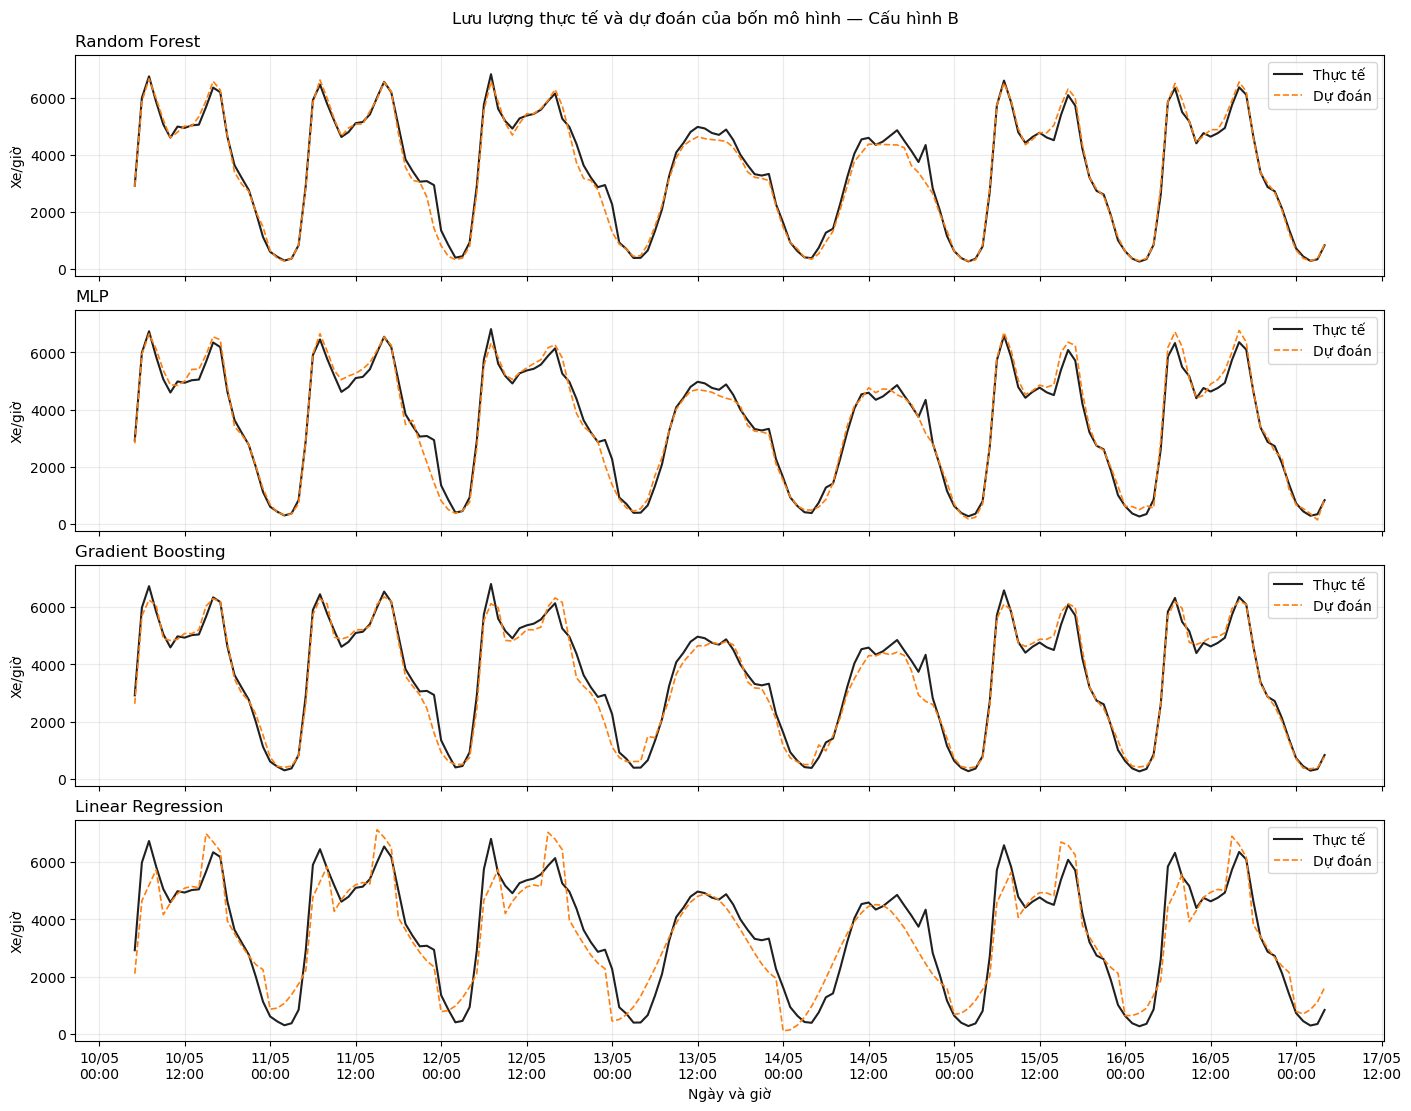

In [11]:
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

HOURS_TO_PLOT = 7 * 24

model_names = [
    "Random Forest",
    "MLP",
    "Gradient Boosting",
    "Linear Regression",
]

prediction_table = predictions.copy()
prediction_table["date_time"] = pd.to_datetime(
    prediction_table["date_time"]
)

plot_index = pd.date_range(
    start=prediction_table["date_time"].min(),
    periods=HOURS_TO_PLOT,
    freq="h",
)

# Giữ NaN ở các giờ thiếu để đường biểu diễn ngắt tại khoảng trống.
plot_data = (
    prediction_table
    .set_index("date_time")
    .reindex(plot_index)
)

fig, axes = plt.subplots(
    len(model_names),
    1,
    figsize=(14, 11),
    sharex=True,
    sharey=True,
    layout="constrained",
    squeeze=False,
)

for ax, name in zip(axes[:, 0], model_names):
    ax.plot(
        plot_data.index,
        plot_data[TARGET],
        color="#202020",
        linewidth=1.5,
        label="Thực tế",
    )

    ax.plot(
        plot_data.index,
        plot_data[name],
        color="tab:orange",
        linestyle="--",
        linewidth=1.2,
        label="Dự đoán",
    )

    ax.set_title(name, loc="left")
    ax.set_ylabel("Xe/giờ")
    ax.grid(alpha=0.25)
    ax.legend(loc="upper right")

axes[-1, 0].xaxis.set_major_locator(
    mdates.HourLocator(byhour=[0, 12])
)
axes[-1, 0].xaxis.set_major_formatter(
    mdates.DateFormatter("%d/%m\n%H:%M")
)
axes[-1, 0].set_xlabel("Ngày và giờ")

fig.suptitle(
    f"Lưu lượng thực tế và dự đoán của bốn mô hình "
    f"— Cấu hình {CONFIG_NAME}"
)
from pathlib import Path

image_dir = (
    Path(PROJECT_ROOT)
    / "experiments"
    / "12-11-2026_ConfigB_4Model_Phuc"
    / "img"
)
image_dir.mkdir(parents=True, exist_ok=True)

image_path = image_dir / f"config_b_4_models_{HOURS_TO_PLOT}h.png"

fig.savefig(
    image_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

print("Đã lưu ảnh:", image_path)
plt.show()

Nhận xét từ hình:
- 2 mô hình Ramdom Forest, MLP có khả năng dự đó vào các cao điểm rất xác với thực tế, 
- ở Ramdom Forest có nhiều giờ cao điểm dự đoán gần như đường vàng dự đoán nằm lên trên đường đen thực tế.